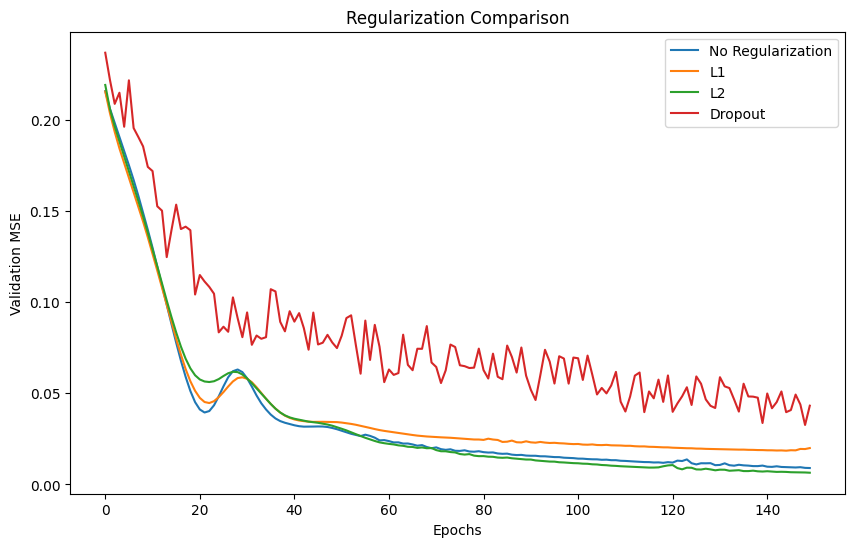

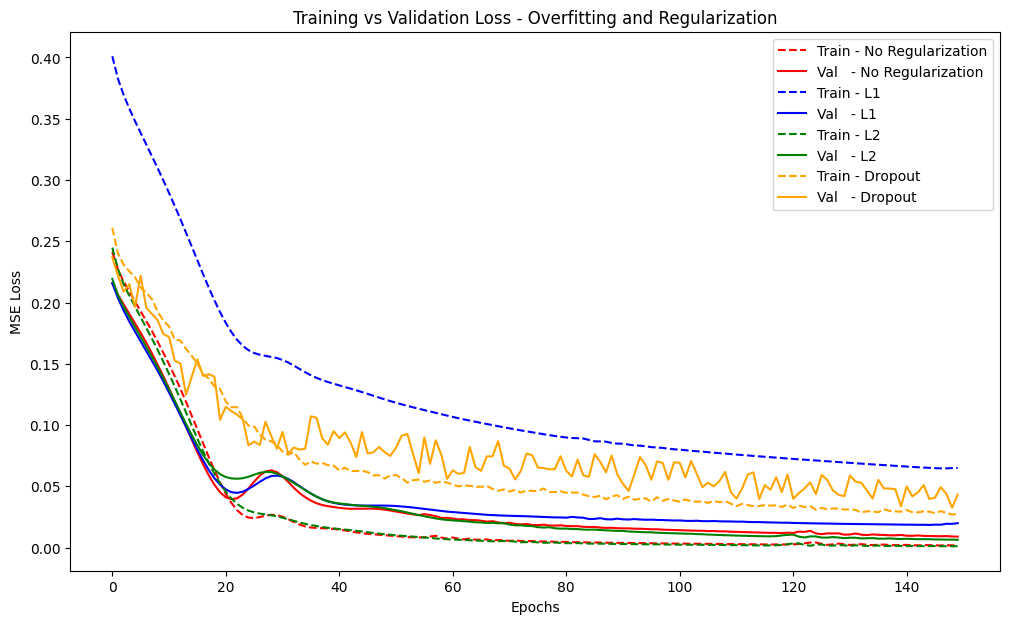

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler


BASE_PATH = Path("Datasets_competition")
DATASET = BASE_PATH / "Func1_dataset1"  

train_df = pd.read_csv(DATASET / "train_points.csv")
val_df   = pd.read_csv(DATASET / "test_points_internal.csv")

X_train = train_df.drop(columns=["z"]).values
y_train = train_df["z"].values
X_val   = val_df.drop(columns=["z"]).values
y_val   = val_df["z"].values

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_t   = torch.tensor(X_val, dtype=torch.float32)
y_val_t   = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

class OverfitNet(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        return self.net(x)

class DropoutNet(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        return self.net(x)

def train(model, optimizer, epochs=150):
    loss_fn = nn.MSELoss()
    tr, va = [], []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X_train_t), y_train_t)
        loss.backward()
        optimizer.step()
        tr.append(loss.item())
        with torch.no_grad():
            va.append(loss_fn(model(X_val_t), y_val_t).item())
    return tr, va

def train_l1(model, optimizer, l1_lambda=1e-4, epochs=150):
    loss_fn = nn.MSELoss()
    tr, va = [], []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X_train_t), y_train_t)
        l1_penalty = sum(p.abs().sum() for p in model.parameters())
        loss = loss + l1_lambda * l1_penalty
        loss.backward()
        optimizer.step()
        tr.append(loss.item())
        with torch.no_grad():
            va.append(loss_fn(model(X_val_t), y_val_t).item())
    return tr, va

# Overfitting model 
model_overfit = OverfitNet(X_train.shape[1])
opt_overfit = optim.Adam(model_overfit.parameters(), lr=0.001)
loss_o, val_o = train(model_overfit, opt_overfit)

# L1 Regularization
model_l1 = OverfitNet(X_train.shape[1])
opt_l1 = optim.Adam(model_l1.parameters(), lr=0.001)
loss_l1, val_l1 = train_l1(model_l1, opt_l1)

# L2 Regularization
model_l2 = OverfitNet(X_train.shape[1])
opt_l2 = optim.Adam(model_l2.parameters(), lr=0.001, weight_decay=1e-4)
loss_l2, val_l2 = train(model_l2, opt_l2)

# Dropout
model_do = DropoutNet(X_train.shape[1])
opt_do = optim.Adam(model_do.parameters(), lr=0.001)
loss_do, val_do = train(model_do, opt_do)

# Plot (cost-function comparison)
plt.figure(figsize=(10,6))
plt.plot(val_o, label="No Regularization")
plt.plot(val_l1, label="L1")
plt.plot(val_l2, label="L2")
plt.plot(val_do, label="Dropout")
plt.xlabel("Epochs")
plt.ylabel("Validation MSE")
plt.title("Regularization Comparison")
plt.legend()
plt.show()

# Plot training vs validation loss for all models
plt.figure(figsize=(12,7))

# Overfitting model
plt.plot(loss_o, label="Train - No Regularization", linestyle='--', color='red')
plt.plot(val_o,  label="Val   - No Regularization", linestyle='-', color='red')

# L1 Regularization
plt.plot(loss_l1, label="Train - L1", linestyle='--', color='blue')
plt.plot(val_l1,  label="Val   - L1", linestyle='-', color='blue')

# L2 Regularization
plt.plot(loss_l2, label="Train - L2", linestyle='--', color='green')
plt.plot(val_l2,  label="Val   - L2", linestyle='-', color='green')

# Dropout
plt.plot(loss_do, label="Train - Dropout", linestyle='--', color='orange')
plt.plot(val_do,  label="Val   - Dropout", linestyle='-', color='orange')

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss - Overfitting and Regularization")
plt.legend()
plt.show()



# Modifications to deliberately induce overfitting:
# - Use of a high-capacity neural network (3 hidden layers with 128 neurons each)
# - Absence of any regularization in the baseline model
# - Training over a relatively large number of epochs (150)
# These changes allow the network to strongly fit the training data, including noise, leading to poor generalization.

# Diagnosis and observation of overfitting:
# - Training loss consistently decreases while validation loss stops improving or increases
# - A clear divergence between training and validation MSE is observed
# - The large number of trainable parameters relative to dataset size increases model variance
# In this implementation, overfitting is identified through training–validation loss divergence plots.

# Regularization setup and parameter selection:
# - L1 regularization with l1_lambda = 1e-4 to promote sparsity while maintaining convergence
# - L2 regularization using weight_decay = 1e-4 to constrain weight magnitudes
# - Dropout with probability p = 0.3 to reduce neuron co-adaptation
# These values were selected empirically to reduce overfitting without causing underfitting.

# Influence on convergence behavior:
# - L1 regularization slows the growth of large weights and encourages sparse solutions
# - L2 regularization stabilizes optimization by penalizing large weights
# - Dropout introduces stochasticity during training, slightly slowing convergence
# Compared to the unregularized model, all methods produce smoother validation loss curves.

# Generalization performance:
# - All regularization techniques reduce the gap between training and validation loss
# - L2 and Dropout achieve the lowest validation errors
# - The unregularized model attains the lowest training loss but the highest validation loss

# Comparative analysis:
# - No regularization: strong overfitting and poor generalization
# - L1: moderate overfitting reduction with some loss of flexibility
# - L2: effective balance between bias and variance with stable convergence
# - Dropout: strongest improvement in generalization, particularly for noisy data
# Overall, L2 and Dropout provide the best results, with Dropout performing slightly better for this dataset.